# Logistic regression: interpretation

The final elastic-net logistic regression is loaded from MLflow exactly as `python -m churn.train_logistic` saved it:
nothing is refitted here.

1. **Odds ratios**: what each column does to the odds of churn, all other columns held fixed.
2. **Binned residuals**: where a straight line in a variable misses the real shape of its effect.
3. **Results on the hold-out**: PR-AUC, precision, recall, F1 and the confusion matrix.

In [1]:
import os
import warnings

# Quieter outputs: no MLflow download bars or hints, no notice about the missing notebook progress widget.
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
# Expected: a level unseen in training shows up in the hold-out set and is pooled with the rare levels.
warnings.filterwarnings("ignore", message="Found unknown categories")

In [2]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

from churn.config import ROOT, load_config
from churn.data import load_raw, split
from churn.model import metrics, split_xy
from churn.plots import CHURNED, INK2, STAYED, set_style
from churn.train_logistic import setup_mlflow

cfg = load_config()
set_style()
setup_mlflow(cfg)

# The most recent final run of the experiment; its model is loaded as saved.
run = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experiment"]],
                         filter_string="tags.mlflow.runName = 'logreg_final'",
                         order_by=["start_time DESC"], max_results=1).iloc[0]
pipe = mlflow.sklearn.load_model(f"runs:/{run.run_id}/model")
run[["params.feature_engineering", "params.C", "params.l1_ratio", "metrics.test_pr_auc", "metrics.test_roc_auc",
     "metrics.test_precision", "metrics.test_recall"]]

params.feature_engineering                   True
params.C                      0.15752196554365352
params.l1_ratio                0.5389719429733358
metrics.test_pr_auc                       0.65106
metrics.test_roc_auc                     0.667646
metrics.test_precision                   0.617936
metrics.test_recall                      0.608959
Name: 0, dtype: object

In [3]:
# The charts use the training set only; the hold-out set appears only in section 3, to redraw the training script's
# single evaluation.
train, test = split(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["target"], cfg["test_size"], cfg["seed"])
X, y = split_xy(train, cfg)

encode = pipe["encode"]
coef = pd.Series(pipe["model"].coef_[0], index=encode.get_feature_names_out())
print(f"{(coef != 0).sum()} of {len(coef)} columns have a non-zero coefficient")

153 of 164 columns have a non-zero coefficient


## 1. Odds ratios

The model adds up `coefficient × value` on the log-odds scale, so `exp(coefficient)` is an **odds ratio**: the number
the odds of churn are multiplied by, **with every other column held fixed**.

- **Numeric variables**: per **one standard deviation**. An odds ratio of 1.3 means odds × 1.3 for one standard
  deviation more; 0.8 means odds × 0.8 (20% lower). The 9 light-tailed variables (`months`, `eqpdays`, `hnd_price`,
  `totmrc_Mean`, ..., listed in config as `logreg.light_tailed`) keep their own unit: days, months, dollars. The other
  69 have long tails and are on the signed-log scale (arcsinh, ≈ log for large values), so one standard deviation
  there is a change in proportion, not a fixed number of minutes.
- **Categorical variables** (and the yes/no flags): the level shown (`variable_level`) **against the reference level**
  of that variable, the first one in alphabetical order (table below). The reference changes how a coefficient
  reads, not the predictions.
- Odds, not probability: on this ~50% sample, odds × 1.3 moves a 50% churn probability to 56.5%.
- These are effects *given all the other columns*. Usage variables are strongly correlated, so a single usage
  coefficient can have the opposite sign to the raw churn rates of the EDA; read a family together.

In [4]:
# The categorical step is the second transformer; drop_idx_ points to each variable's reference level.
_, cat_pipe, cat_cols = encode.transformers_[1]
ohe = cat_pipe[-1]
pd.Series({col: cats[i] for col, cats, i in zip(cat_cols, ohe.categories_, ohe.drop_idx_)},
          name="reference level").to_frame()

,reference level
new_cell,Missing
crclscod,A
asl_flag,N
prizm_social_one,C
area,ATLANTIC SOUTH AREA
dualband,N
refurb_new,N
hnd_webcap,NA
ownrent,Missing
dwlltype,M


In [5]:
# The light-tailed variables keep their own unit: one standard deviation is the step their odds ratio refers to.
light = cfg["logreg"]["light_tailed"]
pd.DataFrame({"1 SD =": encode.named_transformers_["light_tailed"][-1].scale_,
              "odds ratio per SD": np.exp(coef[light]).to_numpy()}, index=light).round(2)

,1 SD =,odds ratio per SD
months,9.66,0.80
eqpdays,257.10,1.15
hnd_price,60.75,0.93
totmrc_Mean,23.60,0.86
truck,0.39,1.01
adults,1.29,1.00
income,1.89,0.99
numbcars,0.53,1.01
lor,3.99,0.92


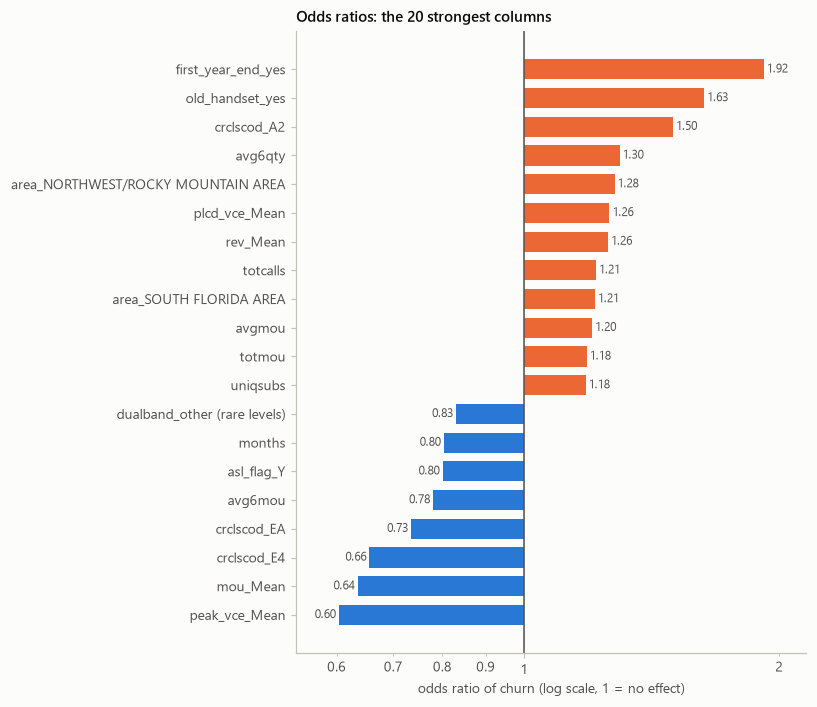

In [6]:
# The 20 columns that move the odds most, in either direction; the other columns are listed in MLflow (features.json).
top = coef[coef.abs().nlargest(20).index].sort_values()
# sklearn names the pooled rare levels "infrequent_sklearn".
odds = np.exp(top).rename(lambda name: name.replace("infrequent_sklearn", "other (rare levels)"))

fig, ax = plt.subplots(figsize=(7.5, 6.5))
# Each bar starts at 1 (no effect) and ends at the odds ratio: right = more churn, left = less churn.
ax.barh(odds.index, odds - 1, left=1, height=0.7, color=np.where(odds > 1, CHURNED, STAYED))
ax.axvline(1, color=INK2, linewidth=1)
ax.margins(x=0.1)  # room for the value labels
ax.set_xscale("log")  # x 2 and x 0.5 are equally far from 1
ax.xaxis.set_major_formatter("{x:g}")
ax.xaxis.set_minor_formatter("{x:g}")
for name, value in odds.items():
    ax.text(value, name, f" {value:.2f} ", va="center", ha="left" if value > 1 else "right", fontsize=8, color=INK2)
ax.set_xlabel("odds ratio of churn (log scale, 1 = no effect)")
ax.set_title("Odds ratios: the 20 strongest columns")
ax.grid(axis="x")
fig.tight_layout()
plt.show()

### What the penalty removed

The 164 columns come from 100 input variables. The L1 part of the penalty set 11 columns exactly to zero: 4 whole
variables, all twins of usage columns the model keeps (`comp_vce_Mean`, `comp_dat_Mean`, `mou_rvce_Mean`,
`peak_dat_Mean`), and 7 rare levels of `crclscod`, `area`, `refurb_new` and `dwllsize`, which fall back on their
reference. 13 more variables are practically null: none of their columns moves the odds by more than 1% (|coefficient|
< 0.01), among them the household fields `adults`, `truck`, `rv`, `forgntvl` and several data-usage counters. In total
17 of 100 variables carry no signal; the other 83 keep a coefficient, because with 80,000 customers the penalty chosen
by CV is weak (C = 0.16).

In [7]:
# Input variable of each column: the categorical variable for its "variable_level" columns, the column otherwise.
variable = coef.index.map(lambda name: next((c for c in cat_cols if name.startswith(c + "_")), name))
largest = coef.abs().groupby(variable).max()  # a variable's strongest column
print(f"{len(largest)} variables, {len(coef)} columns")
print("Removed (every column zero):", sorted(largest[largest == 0].index))
print("Practically null (|coefficient| < 0.01):", sorted(largest[(largest > 0) & (largest < 0.01)].index))
print("Levels set to zero (fall back on the reference):", sorted(coef[(coef == 0) & ~coef.index.isin(largest.index)].index))

100 variables, 164 columns
Removed (every column zero): ['comp_dat_Mean', 'comp_vce_Mean', 'mou_rvce_Mean', 'peak_dat_Mean']
Practically null (|coefficient| < 0.01): ['adults', 'avg6rev', 'callfwdv_Mean', 'custcare_Mean', 'da_Mean', 'datovr_Mean', 'forgntvl', 'mou_cdat_Mean', 'mou_pead_Mean', 'opk_dat_Mean', 'rv', 'truck', 'unan_vce_Mean']
Levels set to zero (fall back on the reference): ['area_DALLAS AREA', 'crclscod_ZA', 'dwllsize_K', 'dwllsize_N', 'dwllsize_O', 'dwllsize_infrequent_sklearn', 'refurb_new_infrequent_sklearn']


## 2. Binned residuals

The residual of a customer is `churned (0/1) − predicted probability`. Customers are grouped into deciles of one
variable, and each point is the mean residual of a decile with a ± 2 standard error bar.

- A model that has the shape of a variable right leaves residuals around 0 in every decile.
- A systematic pattern (a U, a bump, a slope) means a straight line in that variable misses part of its effect:
  this is what tree models such as XGBoost, which draw any shape, can pick up.

Computed on the training set (80,000 customers against ~165 coefficients, so the in-sample fit is barely
optimistic). Ties can merge deciles (`hnd_price` takes a few list prices); customers with a missing value are left
out.

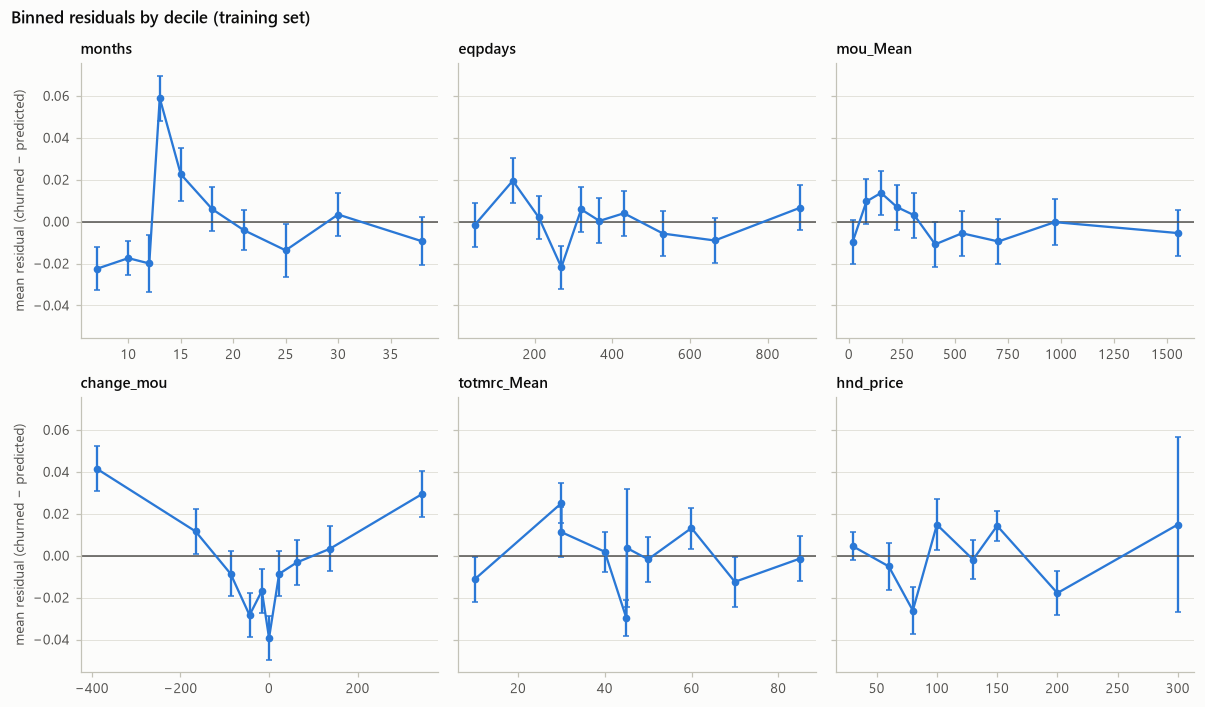

In [8]:
VARIABLES = ["months", "eqpdays", "mou_Mean", "change_mou", "totmrc_Mean", "hnd_price"]
residual = y - pipe.predict_proba(X)[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), sharey=True)
for ax, var in zip(axes.ravel(), VARIABLES):
    deciles = pd.qcut(X[var], 10, duplicates="drop")
    by_decile = residual.groupby(deciles, observed=True)
    x = X[var].groupby(deciles, observed=True).median()  # each decile drawn at its median value
    ax.errorbar(x, by_decile.mean(), yerr=2 * by_decile.sem(), fmt="o-", color=STAYED, markersize=4,
                linewidth=1.5, capsize=2)
    ax.axhline(0, color=INK2, linewidth=1)
    ax.set_title(var)
    ax.grid(axis="y")
for ax in axes[:, 0]:
    ax.set_ylabel("mean residual (churned − predicted)")
fig.suptitle("Binned residuals by decile (training set)", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plt.show()

## What the charts say

- **The two flags are the strongest columns.** Months 11-12 of service multiply the odds of churn by 1.92 and a
  handset of 300 days or more by 1.63, everything else equal. With them the CV PR-AUC rose from 0.629 to 0.647
  (+0.018, about 3.8 fold standard deviations of the base model). The third feature, `mou_vs_lifetime`, adds little
  (odds ratio 0.95): after the signed log the model already has log(minutes) - log(lifetime average).
- **Tenure, handset age and plan price also act in a straight line, on top of the flags.** One standard deviation
  more of tenure (9.7 months) multiplies the odds by 0.80, of handset age (257 days) by 1.15, of monthly recurring
  charge ($23.6) by 0.86.
- **Usage reads as a pair.** More minutes this month (`mou_Mean`, 0.64) and more peak voice calls (0.60) lower the
  odds; a higher lifetime average (`avgmou`, 1.20) raises them: what matters is using less than one's own history.
- **Credit class, area and extra lines** (`crclscod`, `area`, `uniqsubs`) complete the top 20.
- **The residuals show shapes a straight line still misses:**
  - `months`: the risk peak runs past the flag. Months 13-14 churn more than predicted (+6 points), months 6-12
    less (-2 points);
  - `change_mou`: a V. Big drops *and* big rises in minutes churn more than predicted (+3 to +4 points), stable
    usage less (-4): any large change is a warning, while the model can only draw one direction;
  - `eqpdays`: handsets of 240-300 days are over-predicted (-2 points), just before the flag's step;
  - `totmrc_Mean`: $20-30 plans are under-predicted (+2.5 points).

These steps, peaks and V shapes are what a tree model draws by itself, without flags written by hand: the next
step is XGBoost on the same inputs.

## 3. Results on the hold-out

The 20,000 hold-out customers, scored by the final model at the cut 0.5 (`model.threshold` in config, the same cut the
DAG uses for this model). This is the training script's single evaluation, redrawn: nothing is chosen here.

- **PR-AUC** and **ROC-AUC** measure how well the model ranks churners above stayers, whatever the cut.
- **Precision**: share of the flagged customers who really churn. **Recall**: share of all churners who are flagged.
  **F1**: their harmonic mean.
- Confusion matrix rows: the truth (stayed / churned); columns: the model's decision at the cut.

In [9]:
cut = cfg["model"]["threshold"]
X_test, y_test = split_xy(test, cfg)
proba = pipe.predict_proba(X_test)[:, 1]
scores = {**metrics(y_test, proba, cut), "flagged": (proba >= cut).mean()}
pd.Series(scores)[["pr_auc", "roc_auc", "precision", "recall", "f1", "flagged"]].round(3).to_frame(
    f"hold-out, cut {cut}")

,"hold-out, cut 0.5"
pr_auc,0.651
roc_auc,0.668
precision,0.618
recall,0.609
f1,0.613
flagged,0.488


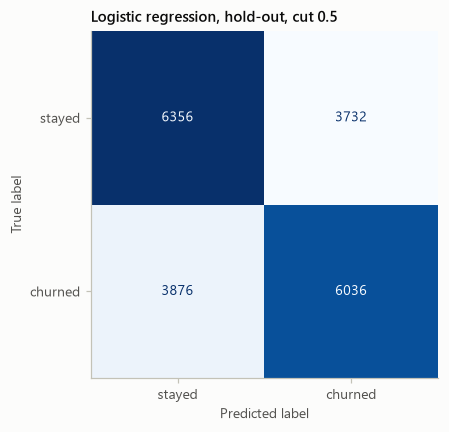

In [10]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, proba >= cut, display_labels=["stayed", "churned"], cmap="Blues",
                                        colorbar=False, ax=ax)
ax.set_title(f"Logistic regression, hold-out, cut {cut}")
fig.tight_layout()
plt.show()

**What it says.**
- **PR-AUC 0.651, ROC-AUC 0.668**: the model ranks churners above stayers better than chance (0.50 for both on
  this ~50% sample), but far from perfectly.
- **At the cut 0.5** it flags 49% of the customers: **precision 0.62, recall 0.61, F1 0.61**. Of the 9912 churners
  it finds 6036 and misses 3876; 3732 of the 10088 stayers are false alarms.
- The cut stays at 0.5 for this model: it is the baseline. XGBoost at the same cut (notebook 03, section 5) finds
  6345 churners (+309) with 3629 false alarms (−103), and ranks better (PR-AUC 0.691).